In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e9/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e9/train.csv
/kaggle/input/competitions/playground-series-s6e9/test.csv


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

In [3]:
df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e9/train.csv")

In [4]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  object 
 9   City_Type                    668665 non-null  object 
 10  Current_Car_Type             668665 non-null  object 
 11  Home_Charging_Possible       668665 non-null  object 
 12  Subsidy_Available            668665 non-null  object 
 13 

In [6]:
df.isnull().sum()

id                             0
Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Gender                         0
City_Type                      0
Current_Car_Type               0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
dtype: int64

In [7]:
df.shape

(668665, 15)

In [8]:
df.describe()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.00000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,334332.00000,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,193027.10321,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,0.00000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,167166.00000,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,334332.00000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,501498.00000,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,668664.00000,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


In [9]:
df.columns

Index(['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km',
       'Number_of_Cars_Owned', 'Charging_Stations_Near_Home',
       'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender',
       'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
       'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV'],
      dtype='object')

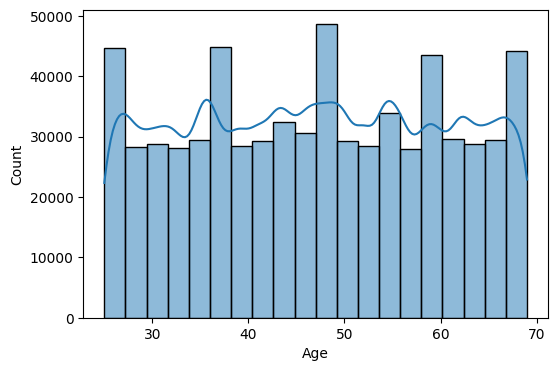

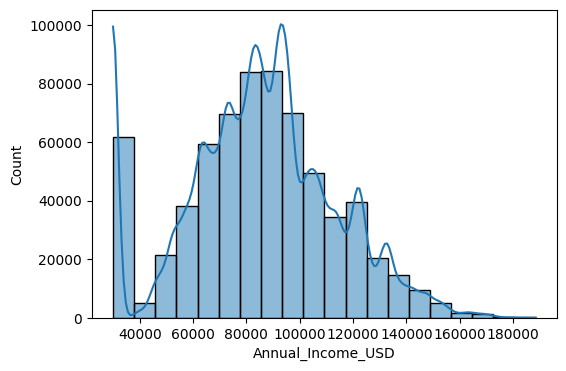

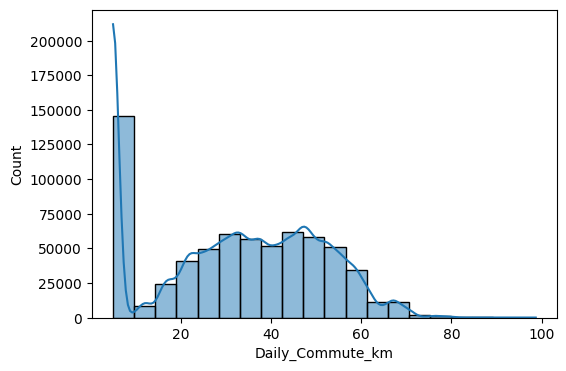

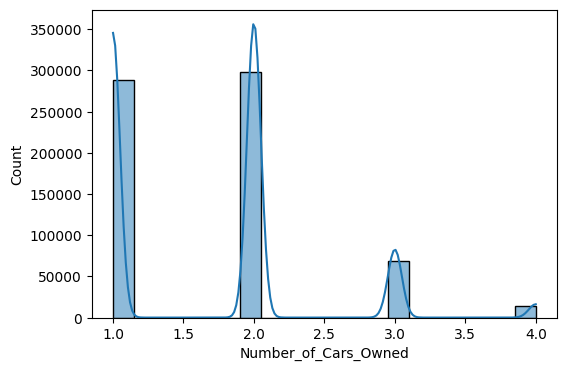

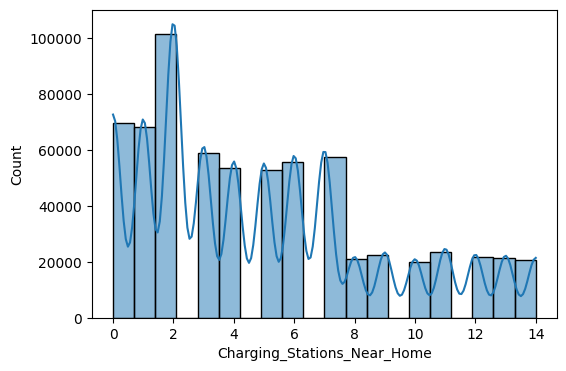

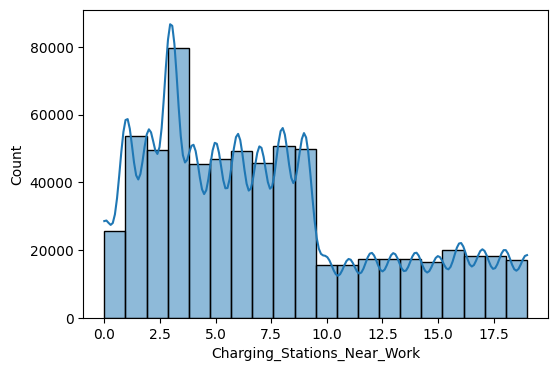

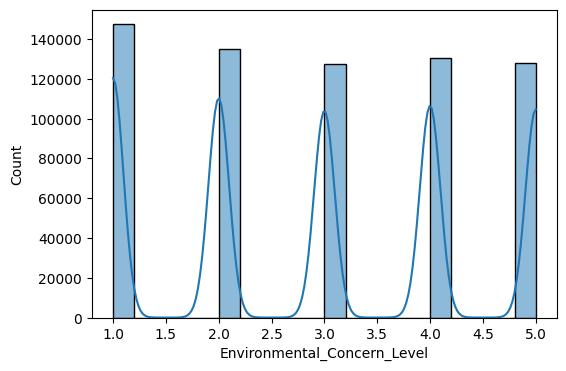

In [10]:
numeric_columns = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 
                   'Number_of_Cars_Owned',
                  'Charging_Stations_Near_Home','Charging_Stations_Near_Work',
                  'Environmental_Concern_Level']

for cols in numeric_columns:
    plt.figure(figsize = (6,4))
    sns.histplot(df[cols], kde = True, bins = 20)

<Axes: xlabel='Number_of_Cars_Owned', ylabel='count'>

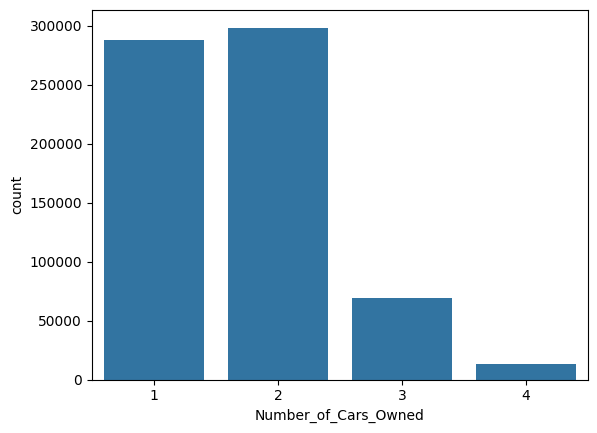

In [11]:
sns.countplot(x = df['Number_of_Cars_Owned'])

<Axes: xlabel='Charging_Stations_Near_Home', ylabel='count'>

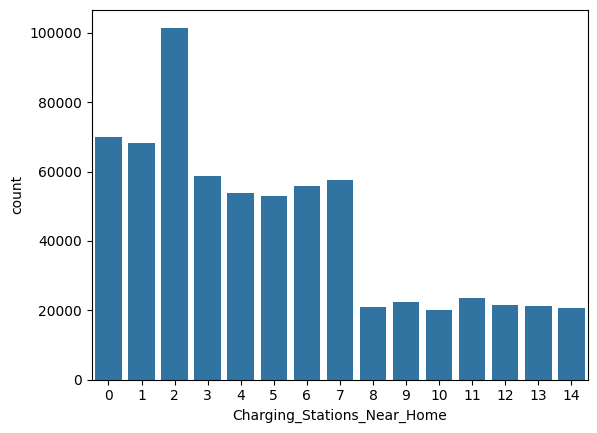

In [12]:
sns.countplot(x = df['Charging_Stations_Near_Home'])

<Axes: xlabel='Charging_Stations_Near_Work', ylabel='count'>

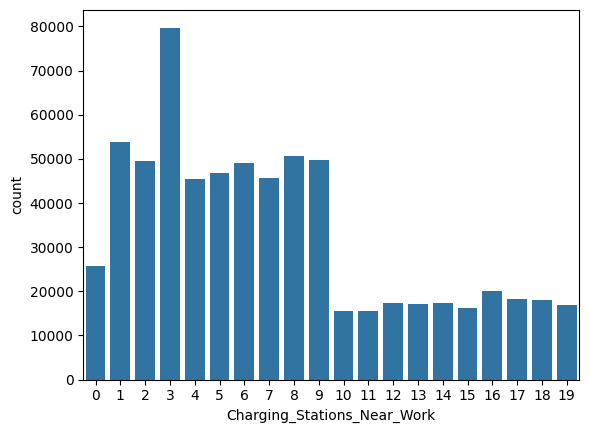

In [13]:
sns.countplot(x = df['Charging_Stations_Near_Work'])

<Axes: xlabel='Environmental_Concern_Level', ylabel='count'>

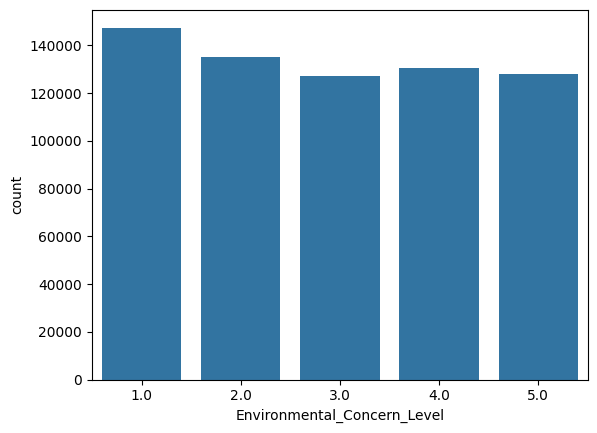

In [14]:
sns.countplot(x = df['Environmental_Concern_Level'])

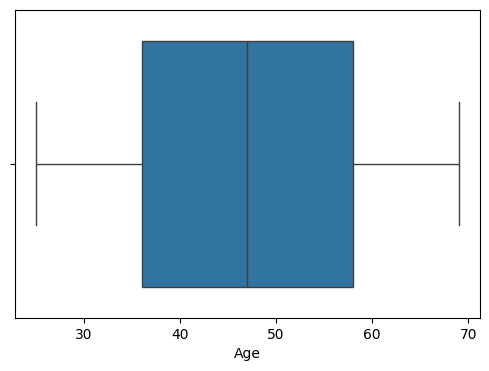

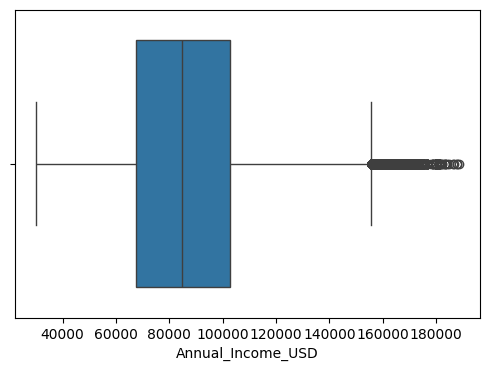

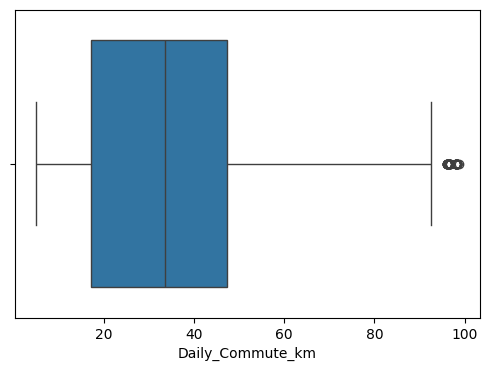

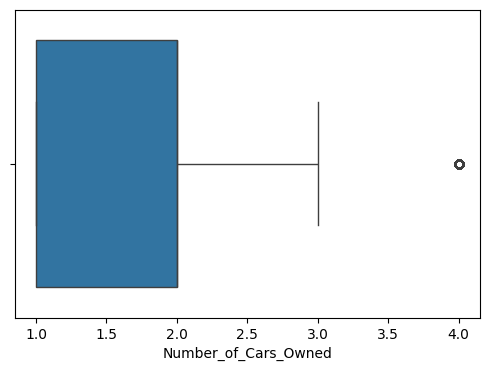

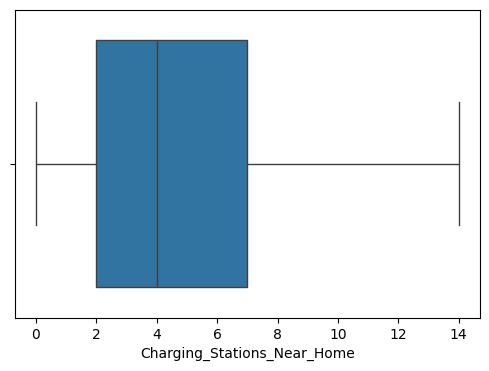

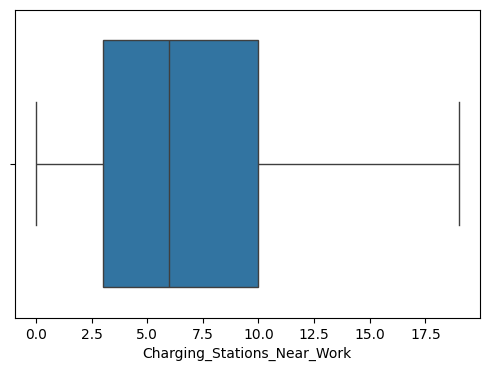

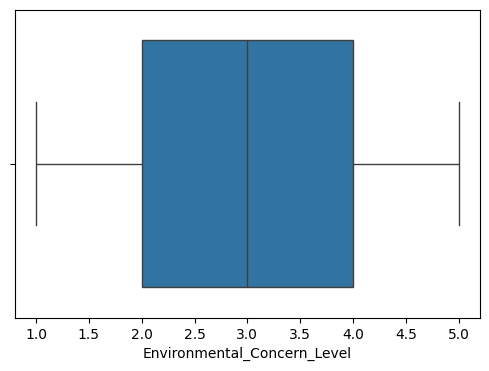

In [15]:
for col in numeric_columns:
    plt.figure(figsize= (6,4))
    sns.boxplot(x = df[col])

<Axes: >

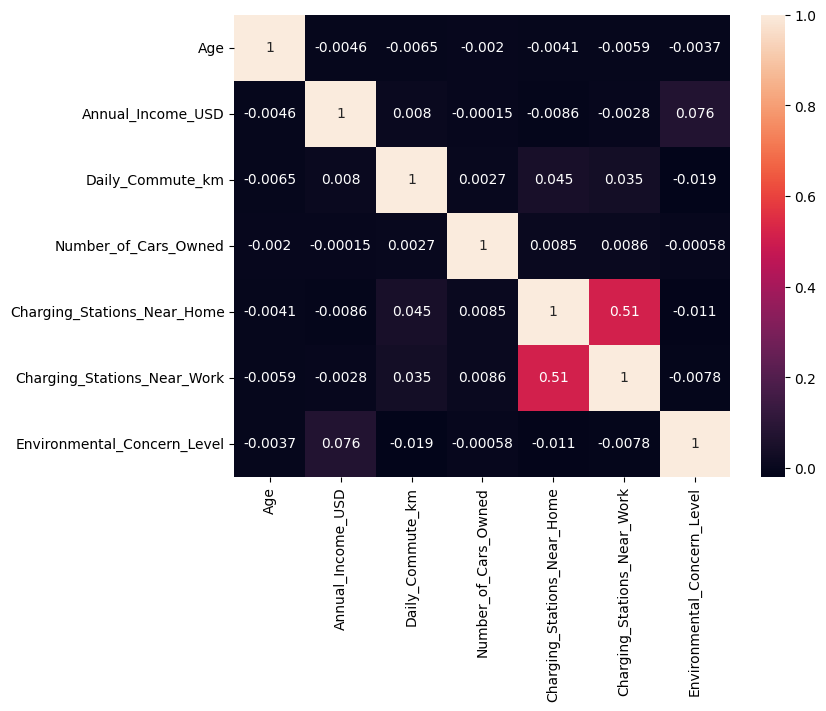

In [16]:
df.drop('id', axis = 1, inplace = True)
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [17]:
df.columns

Index(['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned',
       'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work',
       'Environmental_Concern_Level', 'Gender', 'City_Type',
       'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available',
       'Range_Anxiety_Level', 'Will_Buy_EV'],
      dtype='object')

<Axes: xlabel='Gender', ylabel='count'>

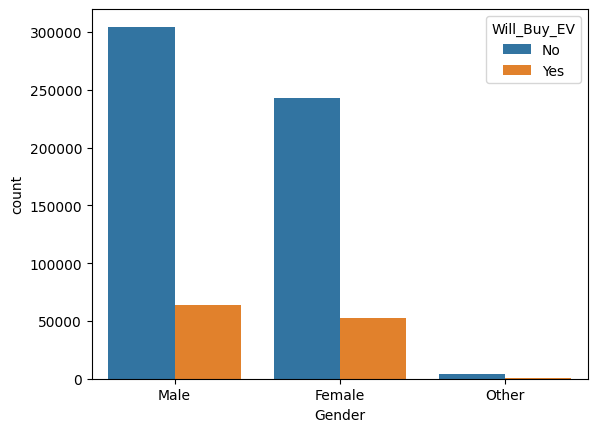

In [18]:
sns.countplot(x = df["Gender"], hue = df['Will_Buy_EV'])

<Axes: xlabel='City_Type', ylabel='count'>

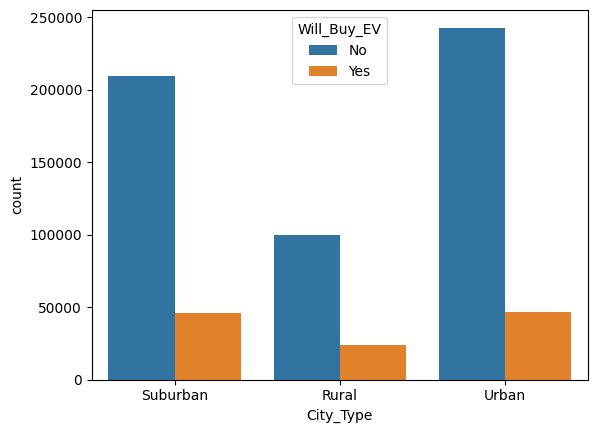

In [19]:
sns.countplot(x = df["City_Type"], hue = df['Will_Buy_EV'])

<Axes: xlabel='Current_Car_Type', ylabel='count'>

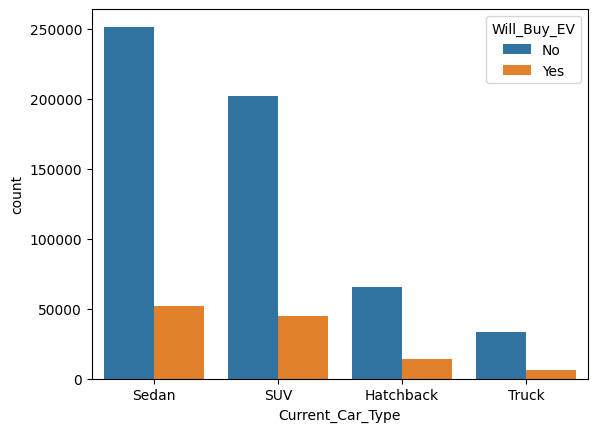

In [20]:
sns.countplot(x = df["Current_Car_Type"], hue = df['Will_Buy_EV'])

<Axes: xlabel='Environmental_Concern_Level', ylabel='count'>

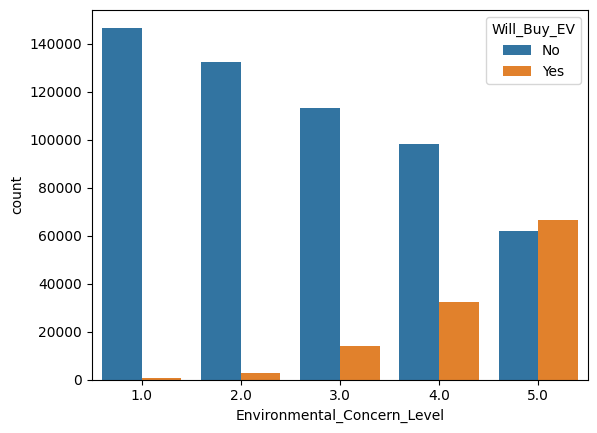

In [21]:
sns.countplot(x = df["Environmental_Concern_Level"], hue = df['Will_Buy_EV'])

<Axes: xlabel='Subsidy_Available', ylabel='count'>

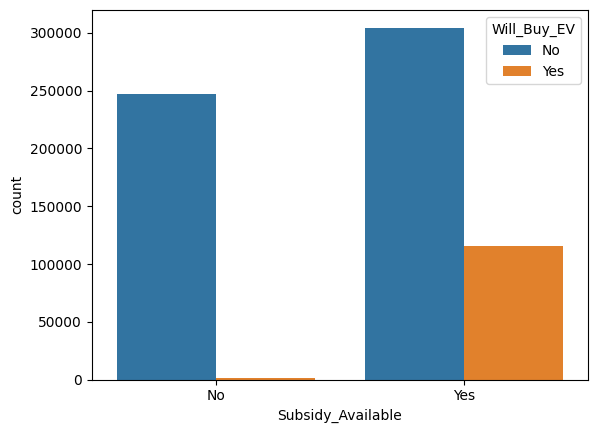

In [22]:
sns.countplot(x = df["Subsidy_Available"], hue = df['Will_Buy_EV'])

<Axes: xlabel='Range_Anxiety_Level', ylabel='count'>

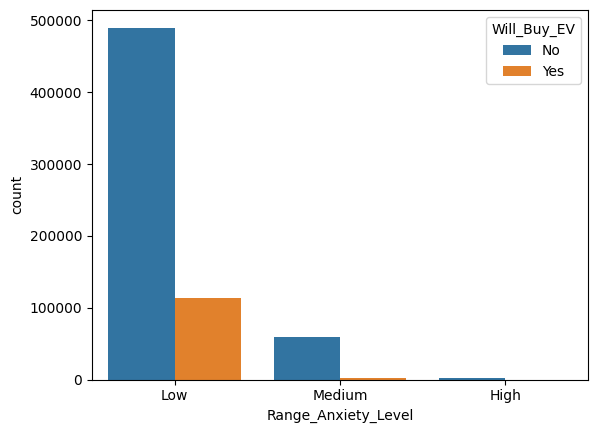

In [23]:
sns.countplot(x = df["Range_Anxiety_Level"], hue = df['Will_Buy_EV'])

In [24]:
df_cleaned = df.copy()

In [25]:
df_cleaned.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [26]:
df_cleaned['Gender'].value_counts()

Gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64

In [27]:
df_encoded = pd.get_dummies(df_cleaned, columns = ['Gender', 'City_Type', 'Current_Car_Type'])

In [28]:
df_encoded.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,66,92887.0,23.4,2,3,7,1.0,Yes,No,Low,...,False,True,False,False,True,False,False,False,True,False
1,38,30000.0,5.0,1,2,2,4.0,Yes,No,Low,...,False,True,False,True,False,False,False,True,False,False
2,26,94389.0,36.8,1,8,15,5.0,No,Yes,Low,...,True,False,False,False,False,True,False,False,True,False
3,66,73580.0,23.7,2,6,9,3.0,Yes,No,Low,...,False,True,False,False,True,False,True,False,False,False
4,54,57898.0,50.8,1,2,3,3.0,Yes,No,Low,...,False,True,False,False,True,False,True,False,False,False


In [29]:
mapping = {
    'Low' : 0,
    'Medium' : 1,
    'High' : 2
}

df_encoded['Range_Anxiety_Level'] = df_encoded['Range_Anxiety_Level'].map(mapping)

In [30]:
df_encoded.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,66,92887.0,23.4,2,3,7,1.0,Yes,No,0,...,False,True,False,False,True,False,False,False,True,False
1,38,30000.0,5.0,1,2,2,4.0,Yes,No,0,...,False,True,False,True,False,False,False,True,False,False
2,26,94389.0,36.8,1,8,15,5.0,No,Yes,0,...,True,False,False,False,False,True,False,False,True,False
3,66,73580.0,23.7,2,6,9,3.0,Yes,No,0,...,False,True,False,False,True,False,True,False,False,False
4,54,57898.0,50.8,1,2,3,3.0,Yes,No,0,...,False,True,False,False,True,False,True,False,False,False


In [31]:
df_encoded['Subsidy_Available'].value_counts()

Subsidy_Available
Yes    419909
No     248756
Name: count, dtype: int64

In [32]:
maps = {
    'Yes' : 1,
    'No' : 0
}

df_encoded['Home_Charging_Possible'] = df_encoded['Home_Charging_Possible'].map(maps)
df_encoded['Subsidy_Available'] = df_encoded['Subsidy_Available'].map(maps)

In [33]:
df_encoded.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,66,92887.0,23.4,2,3,7,1.0,1,0,0,...,False,True,False,False,True,False,False,False,True,False
1,38,30000.0,5.0,1,2,2,4.0,1,0,0,...,False,True,False,True,False,False,False,True,False,False
2,26,94389.0,36.8,1,8,15,5.0,0,1,0,...,True,False,False,False,False,True,False,False,True,False
3,66,73580.0,23.7,2,6,9,3.0,1,0,0,...,False,True,False,False,True,False,True,False,False,False
4,54,57898.0,50.8,1,2,3,3.0,1,0,0,...,False,True,False,False,True,False,True,False,False,False


In [34]:
df_encoded['Will_Buy_EV'] = df_encoded['Will_Buy_EV'].map(maps)

In [35]:
df_encoded = df_encoded.astype(int)

In [36]:
df_encoded.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,66,92887,23,2,3,7,1,1,0,0,...,0,1,0,0,1,0,0,0,1,0
1,38,30000,5,1,2,2,4,1,0,0,...,0,1,0,1,0,0,0,1,0,0
2,26,94389,36,1,8,15,5,0,1,0,...,1,0,0,0,0,1,0,0,1,0
3,66,73580,23,2,6,9,3,1,0,0,...,0,1,0,0,1,0,1,0,0,0
4,54,57898,50,1,2,3,3,1,0,0,...,0,1,0,0,1,0,1,0,0,0


## Applying StandardScaler for Continous Values

In [37]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Age','Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned',
       'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level',
           'Range_Anxiety_Level']

df_scaled = df_encoded.copy()
scaler = StandardScaler()

df_scaled[num_cols] = scaler.fit_transform(df_encoded[num_cols])
df_scaled.head()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,...,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,1.472636,0.283361,-0.473527,0.394055,-0.499233,-0.033994,-1.354316,1,0,-0.321865,...,0,1,0,0,1,0,0,0,1,0
1,-0.702048,-1.911800,-1.442006,-0.977170,-0.753891,-0.998012,0.744881,1,0,-0.321865,...,0,1,0,1,0,0,0,1,0,0
2,-1.634055,0.335791,0.225930,-0.977170,0.774056,1.508436,1.444613,0,1,-0.321865,...,1,0,0,0,0,1,0,0,1,0
3,1.472636,-0.390577,-0.473527,0.394055,0.264740,0.351613,0.045149,1,0,-0.321865,...,0,1,0,0,1,0,1,0,0,0
4,0.540629,-0.937980,0.979191,-0.977170,-0.753891,-0.805209,0.045149,1,0,-0.321865,...,0,1,0,0,1,0,1,0,0,0


## Feature Extraction and Importance

* Running Random forest to see overall importance

In [38]:
from sklearn.ensemble import RandomForestClassifier

X = df_encoded.drop('Will_Buy_EV', axis = 1)
y = df_encoded['Will_Buy_EV']

rf = RandomForestClassifier(
    n_estimators = 200,
    random_state = 42,
    n_jobs = -1
)

rf.fit(X,y)

importance = pd.Series(
    rf.feature_importances_,
    index = X.columns
).sort_values(ascending = False)

print(importance)

Environmental_Concern_Level    0.276957
Annual_Income_USD              0.185654
Subsidy_Available              0.140366
Age                            0.101495
Daily_Commute_km               0.090190
Charging_Stations_Near_Work    0.063738
Charging_Stations_Near_Home    0.053177
Number_of_Cars_Owned           0.026484
Range_Anxiety_Level            0.012375
Current_Car_Type_Sedan         0.007163
Current_Car_Type_SUV           0.006642
Gender_Male                    0.006390
Gender_Female                  0.006353
Home_Charging_Possible         0.005993
Current_Car_Type_Hatchback     0.005139
Current_Car_Type_Truck         0.003288
City_Type_Suburban             0.003154
City_Type_Urban                0.002367
City_Type_Rural                0.001889
Gender_Other                   0.001185
dtype: float64
